# 05 — Adding a region

This example adds region `R2`, duplicates the input data for `R1`, and applies the tutorial's heat-pump capacity limit in `R2`.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

results_dir = Path(r"C:\Users\abduq\Desktop\SSD\MUSE-Tutorials\05-Adding-a-region\model\Results")
mca_capacity = pd.read_csv(results_dir / "MCACapacity.csv")
mca_capacity.head()

,agent,capacity,dst_region,installed,region,sector,technology,type,year
0,A1,10.0,r1,2020,r1,residential,gasboiler,newcapa,2020
1,A1,10.0,r2,2020,r2,residential,gasboiler,newcapa,2020
2,A1,1.0,r1,2020,r1,power,gasCCGT,newcapa,2020
3,A1,1.0,r2,2020,r2,power,gasCCGT,newcapa,2020
4,A1,15.0,r1,2020,r1,gas,gassupply1,newcapa,2020


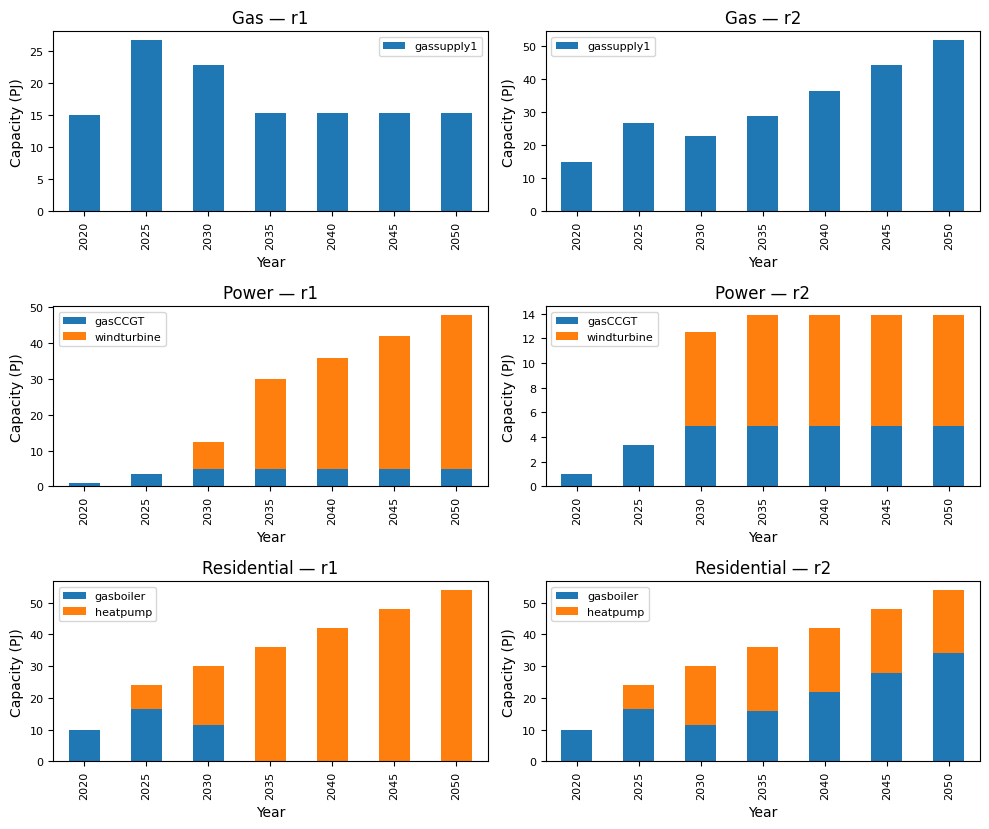

In [4]:
all_years = sorted(mca_capacity["year"].unique())
sectors = list(mca_capacity.groupby("sector"))
regions = sorted(mca_capacity["region"].unique())
fig, axes = plt.subplots(
    len(sectors), len(regions), squeeze=False,
    figsize=(5 * len(regions), 2.8 * len(sectors))
)

for row, (sector_name, sector_data) in enumerate(sectors):
    for column, region in enumerate(regions):
        ax = axes[row, column]
        region_data = sector_data[sector_data["region"] == region]
        sector_capacity = region_data.groupby(
            ["year", "technology"], as_index=False
        )["capacity"].sum()
        if not sector_capacity.empty:
            sector_capacity.pivot(
                index="year", columns="technology", values="capacity"
            ).reindex(all_years, fill_value=0).plot(
                kind="bar", stacked=True, ax=ax
            )
        ax.set_ylabel("Capacity (PJ)")
        ax.set_xlabel("Year")
        ax.set_title(f"{sector_name.capitalize()} — {region}")
        ax.legend(title=None, prop={"size": 8})
        ax.tick_params(axis="both", labelsize=8)

fig.tight_layout()
fig.savefig(results_dir / "MCACapacityByRegion.png", dpi=150, bbox_inches="tight")
plt.show()